In [4]:
!git clone https://github.com/ryszardtuora/kogni_2026.git
!git clone https://github.com/UniversalDependencies/UD_Polish-PDB.git
!python3 -m pip install -r kogni_2026/requirements.txt

fatal: destination path 'kogni_2026' already exists and is not an empty directory.
fatal: destination path 'UD_Polish-PDB' already exists and is not an empty directory.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 79.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [gensim]


# Formaty plików do reprezentacji danych tekstowych

Na dzisiejszych zajęciach będziemy omawiać dwa typy formatów plików które będą przydatne w pracy z tekstem

Będziemy korzystali z biblioteki `pandas` która udostępnia bogaty zakres narzędzi do pracy z tabelami danych

https://pandas.pydata.org/docs/reference/index.html

In [6]:
from pathlib import Path
import pandas
from tqdm import tqdm
from matplotlib import pyplot as plt

Pierwszym formatem z którym będziemy pracować, jest kolumnowy format `conllu`, służący do reprezentacji danych językowych zgodnie ze standardami **Universal Dependencies** (https://universaldependencies.org/introduction.html).

Pliki `conllu` zawierają listy zdań poddane procesowi wielowarstwowego opisu językoznawczego. Każdy z wierszy koresponduje z jednym tokenem, każda z kolumn koresponduje z jedną z warstw opisu. Kolumny są (w ramach wierszy) przedzielone znakiem tabulacji (`\t`), zaś tokeny przynależące do odrębnych zdań oddzielono podwójnym znakiem nowej linii (`\n`). Linie zawierające metadane poprzedzono znakiem `#`.

Korzystając z powyższej specyfikacji, moglibyśmy stosunkowo łatwo napisać własnoręcznie parser konwertujący te dane do obiektów Pythonowych, jednak wygodniej będzie skorzystać z gotowej biblioteki `conllu`:

In [7]:
import conllu

DATA_DIR = Path(".")
UD_DATASET = "UD_Polish-PDB"

filepath = DATA_DIR / UD_DATASET / "pl_pdb-ud-train.conllu"
with open(filepath) as f:
    parsed = conllu.parse(f.read())

print(parsed[0])
print(type(parsed[0][0]), parsed[0][0], parsed[0][0].keys())

TokenList<Mężczyzna, w, czapce, z, daszkiem, trzyma, w, rękach, kamerę, i, spogląda, przez, obiektyw, ., metadata={sent_id: "train-s1", text: "Mężczyzna w czapce z daszkiem trzyma w rękach kamerę i spogląda przez obiektyw.", orig_file_sentence: "CDScorpus_1171_A#118"}>
<class 'conllu.models.Token'> Mężczyzna dict_keys(['id', 'form', 'lemma', 'upos', 'xpos', 'feats', 'head', 'deprel', 'deps', 'misc'])


Parsowanie generuje listę obiektów klasy `TokenList`, z których każda jest iteratorem obiektów klasy `Token`, które zachowują się w sposób zbliżony do słowników Pythona.

Wpierw utwórzmy tabelę (obiekt klasy `DataFrame`) składającą się z jednej kolumny: "tl", zawierającą wszystkie zdania z pliku. Zwróćmy uwagę, że każdy z wierszy jest automatycznie etykietowany indeksem - w tym wypadku liczbą porządkową, możemy je traktować jako numery zdań:

In [8]:
sent_df = pandas.DataFrame({"tl": parsed})
sent_df

,tl
0,"[{'id': 1, 'form': 'Mężczyzna', 'lemma': 'mężc..."
1,"[{'id': 1, 'form': 'Kobieta', 'lemma': 'kobiet..."
2,"[{'id': 1, 'form': 'Chłopiec', 'lemma': 'chłop..."
3,"[{'id': 1, 'form': 'Mężczyzna', 'lemma': 'mężc..."
4,"[{'id': 1, 'form': 'Dwie', 'lemma': 'dwa', 'up..."
...,...
17717,"[{'id': 1, 'form': 'Każda', 'lemma': 'każdy', ..."
17718,"[{'id': 1, 'form': 'Wszyscy', 'lemma': 'wszysc..."
17719,"[{'id': 1, 'form': 'Nie', 'lemma': 'nie', 'upo..."
17720,"[{'id': 1, 'form': 'Jeśli', 'lemma': 'jeśli', ..."


Pierwszą metodą obiektów klasy `DataFrame` jaką poznamy jest `explode`. Ma ona zastosowanie w momencie, gdy wartościami danej kolumny są iteratory. Tworzymy wówczas dłuższą tabelę, gdzie każdy wiersz odpowiada indywidualnemu elementowi z któregoś z iteratorów, możemy o tym myśleć jako o spłaszczeniu zagnieżdżonej listy list. Zwróćmy uwagę, że indeksy nie uległy zmianie, nowe wiersze odziedziczyły je po wierszach z których się wywodzą:

In [9]:
token_dict_df = sent_df.explode("tl")
token_dict_df

,tl
0,"{'id': 1, 'form': 'Mężczyzna', 'lemma': 'mężcz..."
0,"{'id': 2, 'form': 'w', 'lemma': 'w', 'upos': '..."
0,"{'id': 3, 'form': 'czapce', 'lemma': 'czapka',..."
0,"{'id': 4, 'form': 'z', 'lemma': 'z', 'upos': '..."
0,"{'id': 5, 'form': 'daszkiem', 'lemma': 'daszek..."
...,...
17721,"{'id': 10, 'form': 'jakby', 'lemma': 'jakby', ..."
17721,"{'id': 11, 'form': 'przygoda', 'lemma': 'przyg..."
17721,"{'id': 12, 'form': 'go', 'lemma': 'on', 'upos'..."
17721,"{'id': 13, 'form': 'cieszyła', 'lemma': 'ciesz..."


Otrzymujemy w ten sposób tabelę, gdzie każdy z wierszy koresponduje z jednym tokenem.

Na tę chwilę, powyższa tabela nie różni się wiele od listy słowników. Taką strukturę, możemy łatwo przekształcić do nowej instancji `DataFrame`, gdzie każdemu z kluczy słownika zostanie przypisana odrębna kolumna:

In [10]:
token_df = pandas.DataFrame.from_records(token_dict_df["tl"].to_list())
token_df

,id,form,lemma,upos,xpos,feats,head,deprel,deps,misc
0,1,Mężczyzna,mężczyzna,NOUN,subst:sg:nom:m1,"{'Animacy': 'Hum', 'Case': 'Nom', 'Gender': 'M...",6.0,nsubj,"[(nsubj, 6), (nsubj, 11)]",None
1,2,w,w,ADP,prep:loc:nwok,"{'AdpType': 'Prep', 'Variant': 'Short'}",3.0,case,"[(case, 3)]",{'Case': 'Loc'}
2,3,czapce,czapka,NOUN,subst:sg:loc:f,"{'Case': 'Loc', 'Gender': 'Fem', 'Number': 'Si...",1.0,nmod,"[(nmod, 1)]",None
3,4,z,z,ADP,prep:inst:nwok,"{'AdpType': 'Prep', 'Variant': 'Short'}",5.0,case,"[(case, 5)]",{'Case': 'Ins'}
4,5,daszkiem,daszek,NOUN,subst:sg:inst:m3,"{'Animacy': 'Inan', 'Case': 'Ins', 'Gender': '...",3.0,nmod,"[(nmod, 3)]",None
...,...,...,...,...,...,...,...,...,...,...
283690,10,jakby,jakby,SCONJ,comp,{'ConjType': 'Comp'},13.0,mark,"[(mark, 13)]",None
283691,11,przygoda,przygoda,NOUN,subst:sg:nom:f,"{'Case': 'Nom', 'Gender': 'Fem', 'Number': 'Si...",13.0,nsubj,"[(nsubj, 13)]",None
283692,12,go,on,PRON,ppron3:sg:acc:m1:ter:nakc:npraep,"{'Animacy': 'Hum', 'Case': 'Acc', 'Gender': 'M...",13.0,iobj,"[(iobj, 13)]",None
283693,13,cieszyła,cieszyć,VERB,praet:sg:f:imperf,"{'Aspect': 'Imp', 'Gender': 'Fem', 'Mood': 'In...",8.0,ccomp,"[(ccomp, 8)]",{'SpaceAfter': 'No'}


Indeksy nowej tabeli korespondują z numerami tokenów w pliku, natomiast warto zachować odniesienie do oryginalnych zdań. Ponieważ tabele zgadzają sie ze sobą wiersz-do-wiersza (albowiem drugą utworzono przez mapowanie pierwszej), możemy przypisać indeks starej, jako nową kolumnę nowej:

In [11]:
token_df["sent_id"] = token_dict_df.index
token_df

,id,form,lemma,upos,xpos,feats,head,deprel,deps,misc,sent_id
0,1,Mężczyzna,mężczyzna,NOUN,subst:sg:nom:m1,"{'Animacy': 'Hum', 'Case': 'Nom', 'Gender': 'M...",6.0,nsubj,"[(nsubj, 6), (nsubj, 11)]",None,0
1,2,w,w,ADP,prep:loc:nwok,"{'AdpType': 'Prep', 'Variant': 'Short'}",3.0,case,"[(case, 3)]",{'Case': 'Loc'},0
2,3,czapce,czapka,NOUN,subst:sg:loc:f,"{'Case': 'Loc', 'Gender': 'Fem', 'Number': 'Si...",1.0,nmod,"[(nmod, 1)]",None,0
3,4,z,z,ADP,prep:inst:nwok,"{'AdpType': 'Prep', 'Variant': 'Short'}",5.0,case,"[(case, 5)]",{'Case': 'Ins'},0
4,5,daszkiem,daszek,NOUN,subst:sg:inst:m3,"{'Animacy': 'Inan', 'Case': 'Ins', 'Gender': '...",3.0,nmod,"[(nmod, 3)]",None,0
...,...,...,...,...,...,...,...,...,...,...,...
283690,10,jakby,jakby,SCONJ,comp,{'ConjType': 'Comp'},13.0,mark,"[(mark, 13)]",None,17721
283691,11,przygoda,przygoda,NOUN,subst:sg:nom:f,"{'Case': 'Nom', 'Gender': 'Fem', 'Number': 'Si...",13.0,nsubj,"[(nsubj, 13)]",None,17721
283692,12,go,on,PRON,ppron3:sg:acc:m1:ter:nakc:npraep,"{'Animacy': 'Hum', 'Case': 'Acc', 'Gender': 'M...",13.0,iobj,"[(iobj, 13)]",None,17721
283693,13,cieszyła,cieszyć,VERB,praet:sg:f:imperf,"{'Aspect': 'Imp', 'Gender': 'Fem', 'Mood': 'In...",8.0,ccomp,"[(ccomp, 8)]",{'SpaceAfter': 'No'},17721


Spróbujmy przygotować słownik wszystkich występujących w tekście słów. W tym celu wybierzemy kolumnę `lemma` odpowiadającą lematom - formom słownikowym (w szczególności nieodmiennym, oraz znormalizowanym co do sposobu zapisu).

Każda z kolumn jest obiektem klasy `Series`, który implementuje szereg interesujących metod. Wiele z tych metod (jak te z których skorzystamy) zwraca nowy obiekt klasy `Series` który to możemy poddawać dalszemu przetwarzaniu.

Skorzystamy z dwóch metod:
1. `drop_duplicates` - która domyślnie usuwa każde (poza pierwszym) wystąpienie wartości w kolumnie
2. `sort_values` - która posortuje wartości w kolumnie

In [12]:
vocab = token_df["lemma"].drop_duplicates().sort_values()
vocab[1000:1050]

,lemma
119465,BMW
188083,BORT
198289,BOT
54810,BOZPN
50622,BP
31387,BRH
131455,BSE
164818,BWA
251150,Baalen
283474,Baath


Jeżeli chcielibyśmy dowiedzieć się czegoś na temat tego, ile jest wystąpień każdej z unikalnych wartości w korpusie, możemy zastosować metodę `value_counts`:

In [13]:
token_df["lemma"].value_counts()

,count
lemma,
.,18325
",",17415
w,8255
być,6307
i,5118
...,...
trójwodny,1
zalepić,1
69,1


## Ćwiczenie 1:

W kolumnie "upos" znajdują się tagi części mowy (Universal Part of Speech). Oblicz UDZIAŁ poszczególnych tagów w badanym korpusie.

In [14]:
#TODO
token_df["upos"].value_counts(normalize = True) # proporcje części mowy

,proportion
upos,
NOUN,0.251252
PUNCT,0.163898
VERB,0.111824
ADP,0.105353
ADJ,0.102279
PRON,0.046776
PROPN,0.033864
ADV,0.032387
PART,0.031255


### Ilustracja prawa Zipfa:

$word frequency \propto  \frac{1}{word ranking}$

Częstość występowania słowa jest proporcjonalna do odwrotności jego miejsca w rankingu.

Policzmy teoretyczną spodziewaną wartość na podstawie miejsca w rankingu, oraz obserwowaną częstość:

Na obiektach klasy `Series` możemy wykonywać zarówno skalarną, jak i wektorową arytmetykę.
`reset_index` przypisuje dla obiektu `DataFrame` indeksy na nowo, zachowując stare indeksowanie jako kolumnę, wykorzystujemy je tutaj by uzyskać wartości rankingu frekwencyjnego.

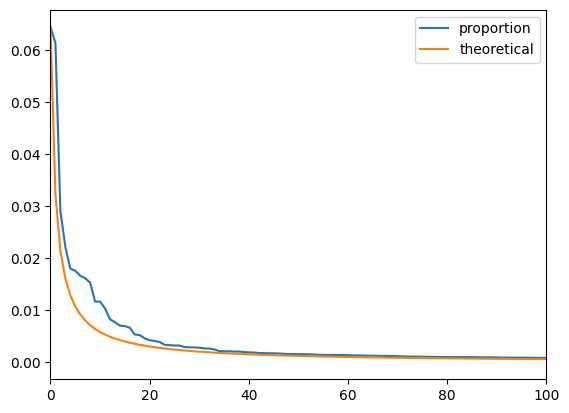

In [15]:
zipf = token_df["lemma"].value_counts(normalize=True).reset_index()
max_prop = zipf["proportion"].max()
zipf["theoretical"] = max_prop / (zipf.index + 1)
zipf_cols = ["proportion", "theoretical"]
for col in zipf_cols:
    zipf[col].plot()


plt.legend(zipf_cols)
plt.xlim(0,100)
plt.show()

Metoda `apply` tworzy nową kolumnę, gdzie wartości są wynikiem zastosowania zadanej funkcji do kolumny wejściowej:

In [16]:
token_df["charlen"] = token_df["form"].apply(len)
token_df[["form", "charlen"]]

,form,charlen
0,Mężczyzna,9
1,w,1
2,czapce,6
3,z,1
4,daszkiem,8
...,...,...
283690,jakby,5
283691,przygoda,8
283692,go,2
283693,cieszyła,8


Często będziemy korzystać z filtrowania tabel przez kolumnę wartości `bool`. Na przykład wybierzmy tylko te tokeny, które otagowano jako przysłówki, lub przymiotniki. Skorzystamy w tym celu z metody `isin` która sprawdza czy wartość w danym wierszu należy do podanego iteratora:

In [17]:
adv_adj_filter = token_df["upos"].isin(["ADV", "ADJ"])
print(adv_adj_filter.iloc[:20])
adv_adj_df = token_df[adv_adj_filter]
adv_adj_df

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
12    False
13    False
14    False
15    False
16     True
17    False
18     True
19    False
Name: upos, dtype: bool


,id,form,lemma,upos,xpos,feats,head,deprel,deps,misc,sent_id,charlen
16,3,długiej,długi,ADJ,adj:sg:loc:f:pos,"{'Case': 'Loc', 'Degree': 'Pos', 'Gender': 'Fe...",6.0,amod,"[(amod, 6)]",{'SpaceAfter': 'No'},1,7
18,5,ciemnej,ciemny,ADJ,adj:sg:loc:f:pos,"{'Case': 'Loc', 'Degree': 'Pos', 'Gender': 'Fe...",3.0,conj,"[(conj, 3), (amod, 6)]",None,1,7
21,8,białym,biały,ADJ,adj:sg:loc:m3:pos,"{'Animacy': 'Inan', 'Case': 'Loc', 'Degree': '...",9.0,amod,"[(amod, 9)]",None,1,6
25,12,jedną,jeden,ADJ,adj:sg:inst:f:pos,"{'Case': 'Ins', 'Degree': 'Pos', 'Gender': 'Fe...",14.0,amod,"[(amod, 14)]",None,1,5
26,13,dużą,duży,ADJ,adj:sg:inst:f:pos,"{'Case': 'Ins', 'Degree': 'Pos', 'Gender': 'Fe...",14.0,amod,"[(amod, 14)]",None,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...
283647,4,samą,sam,ADJ,adj:sg:acc:f:pos,"{'Case': 'Acc', 'Degree': 'Pos', 'Gender': 'Fe...",3.0,fixed,"[(fixed, 3)]",None,17718,4
283654,11,sądowych,sądowy,ADJ,adj:pl:gen:n:pos,"{'Case': 'Gen', 'Degree': 'Pos', 'Gender': 'Ne...",10.0,amod,"[(amod, 10)]",{'SpaceAfter': 'No'},17718,8
283672,5,jak,jak,ADV,adv:pos,"{'Degree': 'Pos', 'PronType': 'Int'}",7.0,advmod,"[(advmod, 7)]",None,17720,3
283684,4,pozostałej,pozostały,ADJ,adj:sg:gen:f:pos,"{'Case': 'Gen', 'Degree': 'Pos', 'Gender': 'Fe...",5.0,amod,"[(amod, 5)]",None,17721,10


W danych PDB mamy do czynienia z pewnego typu subtelnością - niektóre tokeny są oznaczone jako "subtokeny", wówczas w polu "id" nie mamy pojedynczego inta, lecz tuplę złożoną z dwóch takich intów. Dla prostoty analizy odfiltrujmy je, i utwórzmy nową tabelę.

Następnie wykorzystajmy metodę `apply` tym razem jednak nie jako metodę kolumny (`Series`) lecz całego `DataFrame`. Podając argument `axis=1`, specyfikujemy, że chcemy poruszać się po wierszach, mamy wówczas dostęp do wartości wszystkich z kolumn danego wiersza.

Skorzystamy z dwóch takich kolumn: "id" oznaczającej numer tokenu w zdaniu, oraz "head" oznaczającej id bezpośredniego nadrzędnika dla danego tokenu (wartość 0, jeżeli token jest korzeniem zdania). Różnica między tymi dwoma oznacza "przesunięcie" krawędzi w drzewie zależnościowym, i.e. liczbę tokenów pomiędzy nadrzędnikiem, i danym podrzędnikiem (włącznie z tym ostatnim):

In [18]:
atom_df = token_df[token_df["id"].apply(type) == int]
atom_df["dep_displacement"] = atom_df.apply(
    lambda row: row["head"] - row["id"] if row["head"] else 0, axis=1
)
atom_df[["id", "form", "head", "dep_displacement"]]

/tmp/ipykernel_3099/4262858495.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  atom_df["dep_displacement"] = atom_df.apply(


,id,form,head,dep_displacement
0,1,Mężczyzna,6.0,5.0
1,2,w,3.0,1.0
2,3,czapce,1.0,-2.0
3,4,z,5.0,1.0
4,5,daszkiem,3.0,-2.0
...,...,...,...,...
283690,10,jakby,13.0,3.0
283691,11,przygoda,13.0,2.0
283692,12,go,13.0,1.0
283693,13,cieszyła,8.0,-5.0


Teraz skorzystamy z funkcjonalności służących do agregacji danych:

Metoda `groupby` dzieli tabelę na podtabele, ze względu na wartość kolumny którą podajemy do jako argument. Zwraca ona iterator par: (wartość, podtabela), ale najczęściej nie iterujemy po nich bezpośrednio, lecz korzystamy z metod agregacji danych w ramach grup. Jedną z takich metod jest agregacja przez liczenie unikalnych wartości metodą `value_counts`:

Policzmy dystrybuantę długości (w znakach) słów z podziałem na klasy UPOS. W tym celu przygotowujemy:
1. Dane nt. wystąpień każdej z obserwowanych wartości "charlen", z podziałem na klasy.
2. Wybieramy każdą z interesujących nas klas metodą `loc` (pozwala ona na selekcję ze względu na indeks)
3. W ramach wyselekcjonowanych danych sortujemy je po indeksie (którym są teraz obserwowane wartości "charlen"), i stosujemy metodę `cumsum`, czyli sumę kumulatywną, aby uzyskać dystrybuantę.

upos  charlen
ADJ   9          3911
      10         3529
      8          3330
      11         3069
      7          2951
                 ... 
_     15           12
      4            10
      16            7
      18            3
      17            2
Name: count, Length: 249, dtype: int64


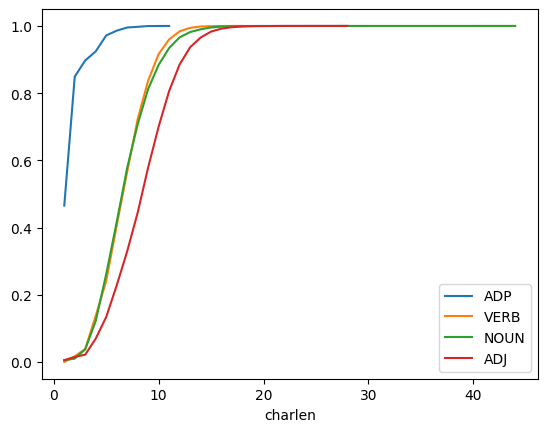

In [19]:
len_count = token_df.groupby("upos")["charlen"].value_counts()
print(len_count)
## cumulative distribution
len_freq = token_df.groupby("upos")["charlen"].value_counts(normalize=True)
POS = ["ADP", "VERB", "NOUN", "ADJ"]
for pos in POS:
    cdist = len_freq.loc[pos].sort_index().cumsum()
    cdist.plot()

plt.legend(POS)
plt.show()

## Ćwiczenie 2:

Policz średnią długość krawędzi ("dep_displacement") w każdej z grup wyodrębnionych ze względu na tag UPOS.

In [20]:
atom_df.groupby("upos")["dep_displacement"].mean()

,dep_displacement
upos,
ADJ,-0.232423
ADP,1.363959
ADV,0.827601
AUX,0.548255
CCONJ,2.160129
DET,1.246436
INTJ,1.432624
NOUN,-1.402096
NUM,1.031708


## Ćwiczenie 3:

Wybierz z całej tabeli te wiersze, które korespondują z tokenami, których lemat występuje min. 10 razy w całym korpusie.
Policz udział tagów UPOS w tak zawężonym zbiorze, a następnie porównaj go (i.e. przedstaw stosunek, korzystając z arytmetyki wektorów) z udziałem w całym korpusie.

In [23]:
over_10 = atom_df["lemma"].value_counts()>= 10
over_10[over_10].index

Index(['.', ',', 'w', 'być', 'i', 'na', 'się', 'z', '-', 'on',
       ...
       'bezrobotny', 'pudełko', 'kropla', 'cywilizacja', 'Królestwo', 'Berlin',
       'medycyna', 'ojczyzna', 'przelatywać', 'śmigłowiec'],
      dtype='object', name='lemma', length=3156)

In [ ]:
freq_tokens = atom_df[atom_df["lemma"].isin(most_freq)]
freq_tokens["upos"].value_counts(normalize=True) / atom_df["upos"].value_counts(normalize=True)

Bardzo istotną metodą pracy z tabelami, jest możliwość łączenia ich, w oparciu o znajdowane w nich wartości.

Najczęściej wartościami takimi są różnego rodzaju identyfikatory, wyobraźmy sobie np. że mamy dwie tabele dot. produktów w sklepie: w pierwszej znajdują się dane nt. samych produktów (np. ich cena, masa), w drugiej dane nt. producentów (np. kraj siedziby). W każdej z tych tabel jest także kolumna zawierająca identyfikator producenta. Możemy połączyć dwie tabele **po** kluczu identyfikatora, aby w jednej tabeli mieć sparowane dane z obu źródeł, i.e. będziemy w stanie np. dowiedzieć się z jakiego kraju pochodzi dany produkt.

W `pandas` jedną z metod która umożliwia takie operacje jest `merge`. W naszym wypadku będziemy łączyli tabelę samą ze sobą, jednak połączenie będzie się odbywało między różnymi wierszami. Kluczem po którym będziemy łączyli tabele, będzie para `("sent_id", "head")` dla lewej tabeli, i `("sent_id", "id")`. Oznacza to, że dla każdego wiersza z lewej tabeli, będziemy znajdowali wiersz z prawej tabeli taki, że wartości "sent_id" są identyczne w obu, zaś wartość "head" z lewego wiersza jest tożsama z wartością "id" w prawym.

Albo mówiąc po prostu, połączymy podrzędniki z ich nadrzędnikami.

dodatkowo podajemy wartość dla parametru `suffixes`, która określi jak przemianować identycznie brzmiące klucze z lewej i prawej tabeli:

In [24]:
dep_df = atom_df.merge(
    atom_df,
    left_on=("sent_id", "head"),
    right_on=("sent_id", "id"),
    suffixes=("_child", "_head"),
)
dep_df

,id_child,form_child,lemma_child,upos_child,xpos_child,feats_child,head_child,deprel_child,deps_child,misc_child,...,lemma_head,upos_head,xpos_head,feats_head,head_head,deprel_head,deps_head,misc_head,charlen_head,dep_displacement_head
0,1,Mężczyzna,mężczyzna,NOUN,subst:sg:nom:m1,"{'Animacy': 'Hum', 'Case': 'Nom', 'Gender': 'M...",6.0,nsubj,"[(nsubj, 6), (nsubj, 11)]",None,...,trzymać,VERB,fin:sg:ter:imperf,"{'Aspect': 'Imp', 'Mood': 'Ind', 'Number': 'Si...",0.0,root,"[(root, 0)]",None,6,0.0
1,2,w,w,ADP,prep:loc:nwok,"{'AdpType': 'Prep', 'Variant': 'Short'}",3.0,case,"[(case, 3)]",{'Case': 'Loc'},...,czapka,NOUN,subst:sg:loc:f,"{'Case': 'Loc', 'Gender': 'Fem', 'Number': 'Si...",1.0,nmod,"[(nmod, 1)]",None,6,-2.0
2,3,czapce,czapka,NOUN,subst:sg:loc:f,"{'Case': 'Loc', 'Gender': 'Fem', 'Number': 'Si...",1.0,nmod,"[(nmod, 1)]",None,...,mężczyzna,NOUN,subst:sg:nom:m1,"{'Animacy': 'Hum', 'Case': 'Nom', 'Gender': 'M...",6.0,nsubj,"[(nsubj, 6), (nsubj, 11)]",None,9,5.0
3,4,z,z,ADP,prep:inst:nwok,"{'AdpType': 'Prep', 'Variant': 'Short'}",5.0,case,"[(case, 5)]",{'Case': 'Ins'},...,daszek,NOUN,subst:sg:inst:m3,"{'Animacy': 'Inan', 'Case': 'Ins', 'Gender': '...",3.0,nmod,"[(nmod, 3)]",None,8,-2.0
4,5,daszkiem,daszek,NOUN,subst:sg:inst:m3,"{'Animacy': 'Inan', 'Case': 'Ins', 'Gender': '...",3.0,nmod,"[(nmod, 3)]",None,...,czapka,NOUN,subst:sg:loc:f,"{'Case': 'Loc', 'Gender': 'Fem', 'Number': 'Si...",1.0,nmod,"[(nmod, 1)]",None,6,-2.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
263958,10,jakby,jakby,SCONJ,comp,{'ConjType': 'Comp'},13.0,mark,"[(mark, 13)]",None,...,cieszyć,VERB,praet:sg:f:imperf,"{'Aspect': 'Imp', 'Gender': 'Fem', 'Mood': 'In...",8.0,ccomp,"[(ccomp, 8)]",{'SpaceAfter': 'No'},8,-5.0
263959,11,przygoda,przygoda,NOUN,subst:sg:nom:f,"{'Case': 'Nom', 'Gender': 'Fem', 'Number': 'Si...",13.0,nsubj,"[(nsubj, 13)]",None,...,cieszyć,VERB,praet:sg:f:imperf,"{'Aspect': 'Imp', 'Gender': 'Fem', 'Mood': 'In...",8.0,ccomp,"[(ccomp, 8)]",{'SpaceAfter': 'No'},8,-5.0
263960,12,go,on,PRON,ppron3:sg:acc:m1:ter:nakc:npraep,"{'Animacy': 'Hum', 'Case': 'Acc', 'Gender': 'M...",13.0,iobj,"[(iobj, 13)]",None,...,cieszyć,VERB,praet:sg:f:imperf,"{'Aspect': 'Imp', 'Gender': 'Fem', 'Mood': 'In...",8.0,ccomp,"[(ccomp, 8)]",{'SpaceAfter': 'No'},8,-5.0
263961,13,cieszyła,cieszyć,VERB,praet:sg:f:imperf,"{'Aspect': 'Imp', 'Gender': 'Fem', 'Mood': 'In...",8.0,ccomp,"[(ccomp, 8)]",{'SpaceAfter': 'No'},...,tak,ADV,adv:pos,"{'Degree': 'Pos', 'PronType': 'Dem'}",6.0,advmod:cmp,"[(advmod:cmp, 6)]",{'SpaceAfter': 'No'},3,-2.0


W ramach wyodrębnionych grup, możemy przeprowadzać agregację wartości kolumn, korzystamy w tym celu z metody `agg` do której podajemy słownik o strukturze `key: agg_name` gdzie `key` to nazwa kolumny, zaś `agg_name` nazwa funkcji agregującej (np. `mean`, `max`, `var` etc.).

Podzielmy krawędzie ze względu na etykiety UPOS obu ich członów, i obliczmy wariancję przesunięcia względem nadrzędnika:

In [25]:
dep_df.groupby(["upos_child", "upos_head"]).agg({"dep_displacement_child": "var"})

dep_displacement_child
upos_child upos_head                        
ADJ        ADJ                     15.684827
           ADP                      0.000000
           ADV                     23.404110
           DET                      1.037937
           INTJ                          NaN
...                                      ...
X          PART                          NaN
           PROPN                    2.493986
           SYM                           NaN
           VERB                    83.608187
           X                       38.106114

[194 rows x 1 columns]

Możemy wykorzystać różne funkcje agregujące i kolumny na raz:

In [26]:
token_df.groupby("upos").agg({"charlen": "mean", "deprel": "nunique", "id": "count"})

,charlen,deprel,id
upos,,,
ADJ,8.914220,38,29016
ADP,1.914815,13,29888
ADV,6.167936,31,9188
AUX,3.394766,7,7108
CCONJ,1.759032,5,8387
DET,4.982181,33,7576
INTJ,3.879433,4,141
NOUN,7.303834,41,71279
NUM,3.811642,17,2113


Jedną z funkcji agregujących jest `list` która pozwala zgrupować wartości w jeden iterator, możemy w ten sposób zgrupować podrzędniki każdego z tokenów:

In [27]:
child_lists = dep_df.groupby(["id_head", "sent_id"]).agg({"form_head": "first", "form_child": list})
child_lists

form_head             form_child
id_head sent_id                                  
1       0        Mężczyzna               [czapce]
        1          Kobieta             [sukience]
        2         Chłopiec               [kurtce]
        3        Mężczyzna  [kaloszach, chłopcem]
        6        Mężczyzna               [bluzce]
...                    ...                    ...
80      14443      zagrany      [zostać, gitarze]
82      13955    słuchaniu      [przy, śpiewaniu]
        14443      gitarze                   [na]
84      13955    śpiewaniu                    [i]
85      14443      mnóstwa            [i, innych]

[114301 rows x 2 columns]

## Format JSON

Innym ważnym do poznania formatem do pracy z danymi tekstowymi jest JSON. Pozwala on na reprezentację dowolnie zagnieżdżonych struktur o charakterze zbliżonym do Pythonowych słowników. `pandas` pozwala również na pracę z takimi plikami:

In [33]:
SQUAD_DATASET = "SQuAD2.0"
filepath = "kogni_2026/data"/ SQUAD_DATASET / "dev-v2.0.json"
squad_df = pandas.read_json(filepath)
squad_df

TypeError: unsupported operand type(s) for /: 'str' and 'str'

Interesuje nas tylko kolumna "data" która sama ma strukturę słownika:

In [ ]:
squad_df = squad_df["data"].apply(pandas.Series)
squad_df

Każdy z wierszy odpowiada artykułowi, który jest powiązany z listą paragrafów. Zastosujmy metodę `explode`:

In [ ]:
par_df = squad_df.explode("paragraphs")
par_df

Jeszcze głębiej znajdują się klucze "qas" (zawierający listę pytań) i "context" zawierający tekst, do którego pytania te ułożono. Przepiszmy te wartości jako odrębne kolumny korzystając z metody `apply` której podamy anonimową funkcję mającą za zadanie jedynie odpakowanie odpowiednich kluczy:

In [ ]:
par_df["context"] = par_df.apply(lambda x: x["paragraphs"]["context"], axis=1)
par_df["qas"] = par_df.apply(lambda x: x["paragraphs"]["qas"], axis=1)
par_df

Możemy wreszcie wykorzystać `explode` aby uzyskać strukturę, gdzie każdy wiersz będzie zawierał tylko jedno pytanie:

In [ ]:
raw_q_df = par_df.explode("qas")[["title", "qas", "context"]]
raw_q_df

Ponownie, dane w kolumnie "qas" są zagnieżdżone w słownikach. Aby je odpakować, najwygodniej będzie tym razem zastosować konkatenację reszty oryginalnej tabeli, z przetworzonymi wartościami wspomnianej kolumny:

In [ ]:
q_df = pandas.concat([raw_q_df[["title", "context"]], raw_q_df["qas"].apply(pandas.Series)], axis=1)
q_df

## Ćwiczenie 4

Dla każdego pytania, w kolumnie "answers" znajduje się iterator zawierający wiele wartości (będących słownikami), każda z odpowiedzi pochodzi od innego anotatora. Jeżeli odpowiedzi są identyczne, oznacza to zgodę anotatorów, jeżeli różnią się, oznacza różnicę zdań.

Wyodrębnij podzbiór tabeli `q_df` zdefiniowany przez pytania, dla których anotatorzy osiągnęli pełną zgodę co do odpowiedzi

In [ ]:
#TODO
#1. wydobądź odpowiedzi w sposób który pozwala na ich indywidualną analizę, jednocześnie zachowując odniesienie do pytań
#2. znajdź sposób na porównanie ze sobą odpowiedzi
#3. dla każdego pytania policz liczbę unikalnych odpowiedzi
#4. przefiltruj tabelę pytań korzystając z liczby odpowiedzi

# 1 """"
q_df["answers"].explode("answers")["answers"].apply(lambda x:x["text"] + str(x["answer_start"]))